# Model Training: Employee Performance Analysis, INX Future Inc.

**Goals**
1. Train and compare several algorithms that predict an employee's performance rating (2, 3 or 4).
2. Tune the best algorithms and evaluate the winner on data it has never seen.
3. Identify the **top 3 most important factors** (required insight 2).
4. Save a **trained model** that can predict performance from input factors (required insight 3).
5. Build a separate **pre-hire model** using only information available before someone is hired, and report honestly how well it works.
6. Derive simple, explainable **rules** that flag lower performers (the CEO's request for clear indicators).

**Method in brief:** 80/20 stratified train/test split; 5-fold stratified cross-validation on the training part for model selection; test set used once at the end. Because 73% of employees are rated 3, accuracy alone is misleading, so we focus on **macro F1** (average F1 over the three classes, treating every class as equally important).

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, balanced_accuracy_score

pd.set_option('display.max_columns', 60, 'display.width', 200)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
ROOT = Path('../..').resolve()
ART = ROOT/'src'/'models'/'artifacts'; ART.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ROOT/'data'/'processed'/'employee_clean.csv')
print(df.shape)

(1200, 32)


## 1. Prepare inputs

In [2]:
target = 'PerformanceRating'
drop_cols = ['EmpNumber', 'PerformanceLabel', target]
X = df.drop(columns=drop_cols)
y = df[target]

nominal  = ['EducationBackground','MaritalStatus','EmpDepartment','EmpJobRole','Gender','OverTime','Attrition']
ordinal  = ['BusinessTravelFrequency']
numeric  = [c for c in X.columns if c not in nominal + ordinal]

def make_preprocessor():
    # Numbers are standardised, categories one-hot encoded, travel frequency ordered Non-Travel < Rarely < Frequently
    return ColumnTransformer([
        ('num', StandardScaler(), numeric),
        ('nom', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal),
        ('ord', OrdinalEncoder(categories=[['Non-Travel','Travel_Rarely','Travel_Frequently']]), ordinal),
    ])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train class mix %:', (100*y_train.value_counts(normalize=True).sort_index()).round(1).to_dict())
print('Test  class mix %:', (100*y_test.value_counts(normalize=True).sort_index()).round(1).to_dict())
print('Baseline (always predict 3): accuracy =', round((y_test==3).mean(),3), ', macro F1 =', round(f1_score(y_test, np.full(len(y_test),3), average='macro'),3))

Train: (960, 29)  Test: (240, 29)
Train class mix %: {2: 16.1, 3: 72.8, 4: 11.0}
Test  class mix %: {2: 16.2, 3: 72.9, 4: 10.8}
Baseline (always predict 3): accuracy = 0.729 , macro F1 = 0.281


## 2. Compare algorithms with cross-validation

Eight algorithms of different types are compared. Where supported, `class_weight='balanced'` makes mistakes on the smaller classes (2 and 4) count more, to counter the class imbalance.

In [3]:
candidates = {
 'Logistic Regression':      LogisticRegression(max_iter=2000, class_weight='balanced'),
 'K-Nearest Neighbours':     KNeighborsClassifier(n_neighbors=15),
 'Support Vector Machine':   SVC(class_weight='balanced', random_state=RANDOM_STATE),
 'Decision Tree':            DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=RANDOM_STATE),
 'Neural Network (MLP)':     MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1500, random_state=RANDOM_STATE),
 'Random Forest':            RandomForestClassifier(n_estimators=400, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
 'Extra Trees':              ExtraTreesClassifier(n_estimators=400, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
 'Gradient Boosting':        GradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, est in candidates.items():
    pipe = Pipeline([('prep', make_preprocessor()), ('model', est)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy','f1_macro','balanced_accuracy'], n_jobs=-1)
    rows.append((name, s['test_accuracy'].mean(), s['test_f1_macro'].mean(), s['test_f1_macro'].std(), s['test_balanced_accuracy'].mean()))
comparison = pd.DataFrame(rows, columns=['model','accuracy','macro_F1','macro_F1_std','balanced_accuracy']).sort_values('macro_F1', ascending=False).reset_index(drop=True)
comparison.round(3)

,model,accuracy,macro_F1,macro_F1_std,balanced_accuracy
0,Gradient Boosting,0.925,0.885,0.019,0.877
1,Random Forest,0.922,0.879,0.019,0.871
2,Decision Tree,0.881,0.828,0.017,0.863
3,Support Vector Machine,0.804,0.733,0.038,0.784
4,Neural Network (MLP),0.823,0.719,0.028,0.697
5,Logistic Regression,0.760,0.695,0.018,0.779
6,Extra Trees,0.814,0.564,0.038,0.537
7,K-Nearest Neighbours,0.757,0.440,0.025,0.422


Tree-based ensembles are expected to lead, because the relationships here are non-linear (thresholds and interactions such as 'low satisfaction AND no recent promotion') and several features are correlated. The next step tunes the leading ensemble methods.

## 3. Tune the best algorithms

In [4]:
tune_grids = {
 'Random Forest': (RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    {'model__n_estimators':[300], 'model__max_depth':[None,10], 'model__min_samples_leaf':[1,3], 'model__max_features':['sqrt',0.5]}),
 'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
    {'model__n_estimators':[150,300], 'model__learning_rate':[0.05,0.1], 'model__max_depth':[2,3], 'model__subsample':[0.8]}),
}
tuned = {}
for name,(est,grid) in tune_grids.items():
    gs = GridSearchCV(Pipeline([('prep', make_preprocessor()), ('model', est)]), grid, cv=cv, scoring='f1_macro', n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f'{name:18s} best CV macro F1 = {gs.best_score_:.3f}   best settings: {gs.best_params_}')

Random Forest      best CV macro F1 = 0.892   best settings: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}


Gradient Boosting  best CV macro F1 = 0.890   best settings: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 300, 'model__subsample': 0.8}


In [5]:
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_pipe = tuned[best_name].best_estimator_
print('Selected model:', best_name)

Selected model: Random Forest


## 4. Final evaluation on the held-out test set

The test set (240 employees) was not used for any decision above, so these numbers estimate how the model will behave on new employees.

In [6]:
pred = best_pipe.predict(X_test)
metrics = {
  'selected_model': best_name,
  'cv_macro_f1': float(tuned[best_name].best_score_),
  'test_accuracy': float(accuracy_score(y_test, pred)),
  'test_macro_f1': float(f1_score(y_test, pred, average='macro')),
  'test_balanced_accuracy': float(balanced_accuracy_score(y_test, pred)),
  'baseline_accuracy_always_3': float((y_test==3).mean()),
  'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
}
print(json.dumps(metrics, indent=2))
print()
print(classification_report(y_test, pred, target_names=['2 (Good)','3 (Excellent)','4 (Outstanding)']))

{
  "selected_model": "Random Forest",
  "cv_macro_f1": 0.8916082035869308,
  "test_accuracy": 0.9333333333333333,
  "test_macro_f1": 0.9021134421134421,
  "test_balanced_accuracy": 0.8926495726495727,
  "baseline_accuracy_always_3": 0.7291666666666666,
  "n_train": 960,
  "n_test": 240
}

                 precision    recall  f1-score   support

       2 (Good)       0.87      0.87      0.87        39
  3 (Excellent)       0.95      0.96      0.95       175
4 (Outstanding)       0.92      0.85      0.88        26

       accuracy                           0.93       240
      macro avg       0.91      0.89      0.90       240
   weighted avg       0.93      0.93      0.93       240



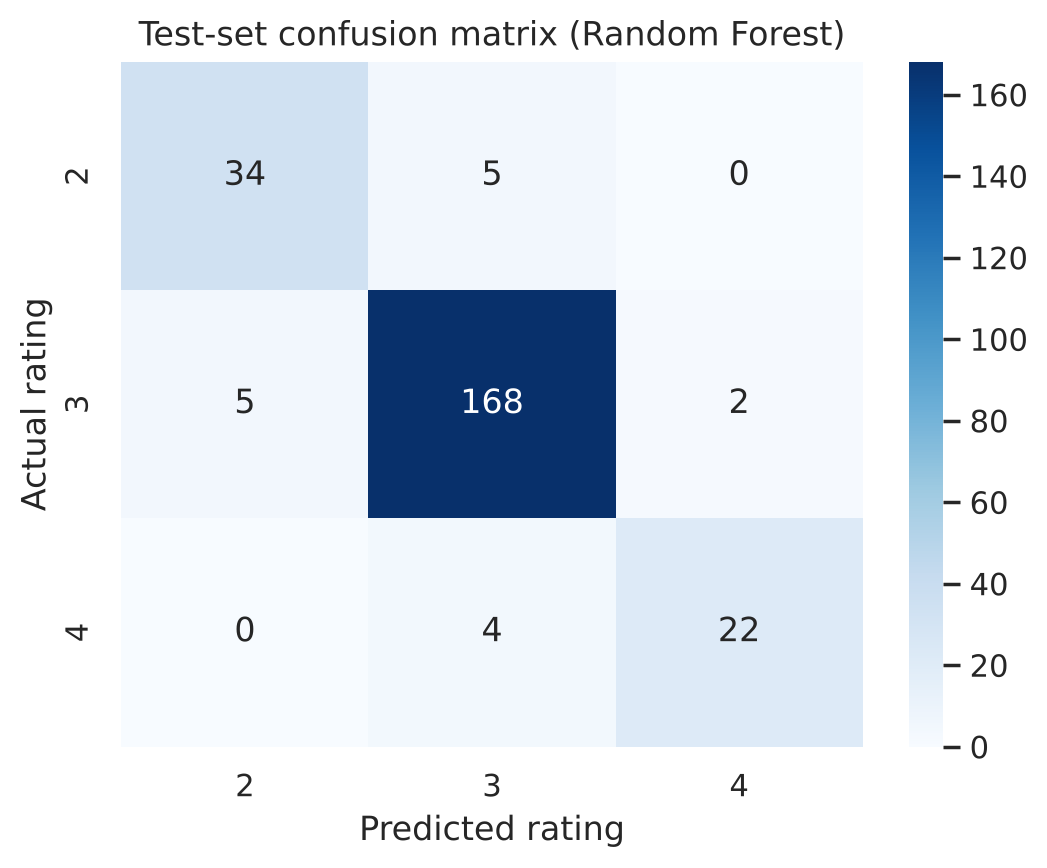

In [7]:
cm = confusion_matrix(y_test, pred, labels=[2,3,4])
fig, ax = plt.subplots(figsize=(5.5,4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[2,3,4], yticklabels=[2,3,4], ax=ax)
ax.set_xlabel('Predicted rating'); ax.set_ylabel('Actual rating'); ax.set_title(f'Test-set confusion matrix ({best_name})')
plt.tight_layout(); plt.show()

**Reading:** on unseen employees the model reaches about **93% accuracy and a macro F1 of 0.90**, against 73% accuracy and 0.28 macro F1 for the 'always 3' guess. It also works on the minority classes: it correctly finds **34 of 39 rating-2 employees (87%)** and **22 of 26 rating-4 employees (85%)**. Its mistakes are almost all between *neighbouring* ratings (2 vs 3, 3 vs 4); on the test set it never confused a 2 with a 4.

*Note: the test set is small (240 employees; 39 rated 2 and 26 rated 4), so these figures carry some uncertainty. The cross-validated macro F1 (0.89) and the out-of-fold results in section 8 (accuracy 0.92) tell the same story.*

## 5. Top factors affecting performance (required insight 2)

Two complementary methods are used:
- **Permutation importance** (main method): shuffle one original column at a time in the *test* data and measure how much the model's macro F1 drops. A large drop means the model relies on that factor. It works on original features (not one-hot pieces), is not biased toward continuous variables, and is evaluated on unseen data.
- **Built-in (impurity) importance**: how much each feature helped the trees split the data, summed back to the original feature. Shown as a cross-check.

In [8]:
perm = permutation_importance(best_pipe, X_test, y_test, scoring='f1_macro', n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({'feature':X_test.columns, 'permutation_importance':perm.importances_mean, 'std':perm.importances_std})

# Built-in importance, summed back to the original column
names = best_pipe.named_steps['prep'].get_feature_names_out()
built = pd.Series(best_pipe.named_steps['model'].feature_importances_, index=names)
def origin(n):
    n = n.split('__',1)[1]
    for c in nominal:
        if n.startswith(c+'_'): return c
    return n
built = built.groupby(origin).sum()
imp['builtin_importance'] = imp['feature'].map(built)
imp = imp.sort_values('permutation_importance', ascending=False).reset_index(drop=True)
imp['rank'] = imp.index + 1
imp.round(4).head(12)

,feature,permutation_importance,std,builtin_importance,rank
0,EmpEnvironmentSatisfaction,0.2950,0.0431,0.2611,1
1,EmpLastSalaryHikePercent,0.2683,0.0192,0.2864,2
2,PromotionDelayRatio,0.0650,0.0221,0.0763,3
3,ExperienceYearsInCurrentRole,0.0444,0.0121,0.0225,4
4,EmpJobRole,0.0271,0.0109,0.0321,5
5,EmpDepartment,0.0234,0.0072,0.0224,6
6,YearsWithCurrManager,0.0124,0.0058,0.0183,7
7,RoleStagnationRatio,0.0097,0.0088,0.0215,8
8,EmpWorkLifeBalance,0.0094,0.0097,0.0474,9
9,ExperienceYearsAtThisCompany,0.0069,0.0044,0.0108,10


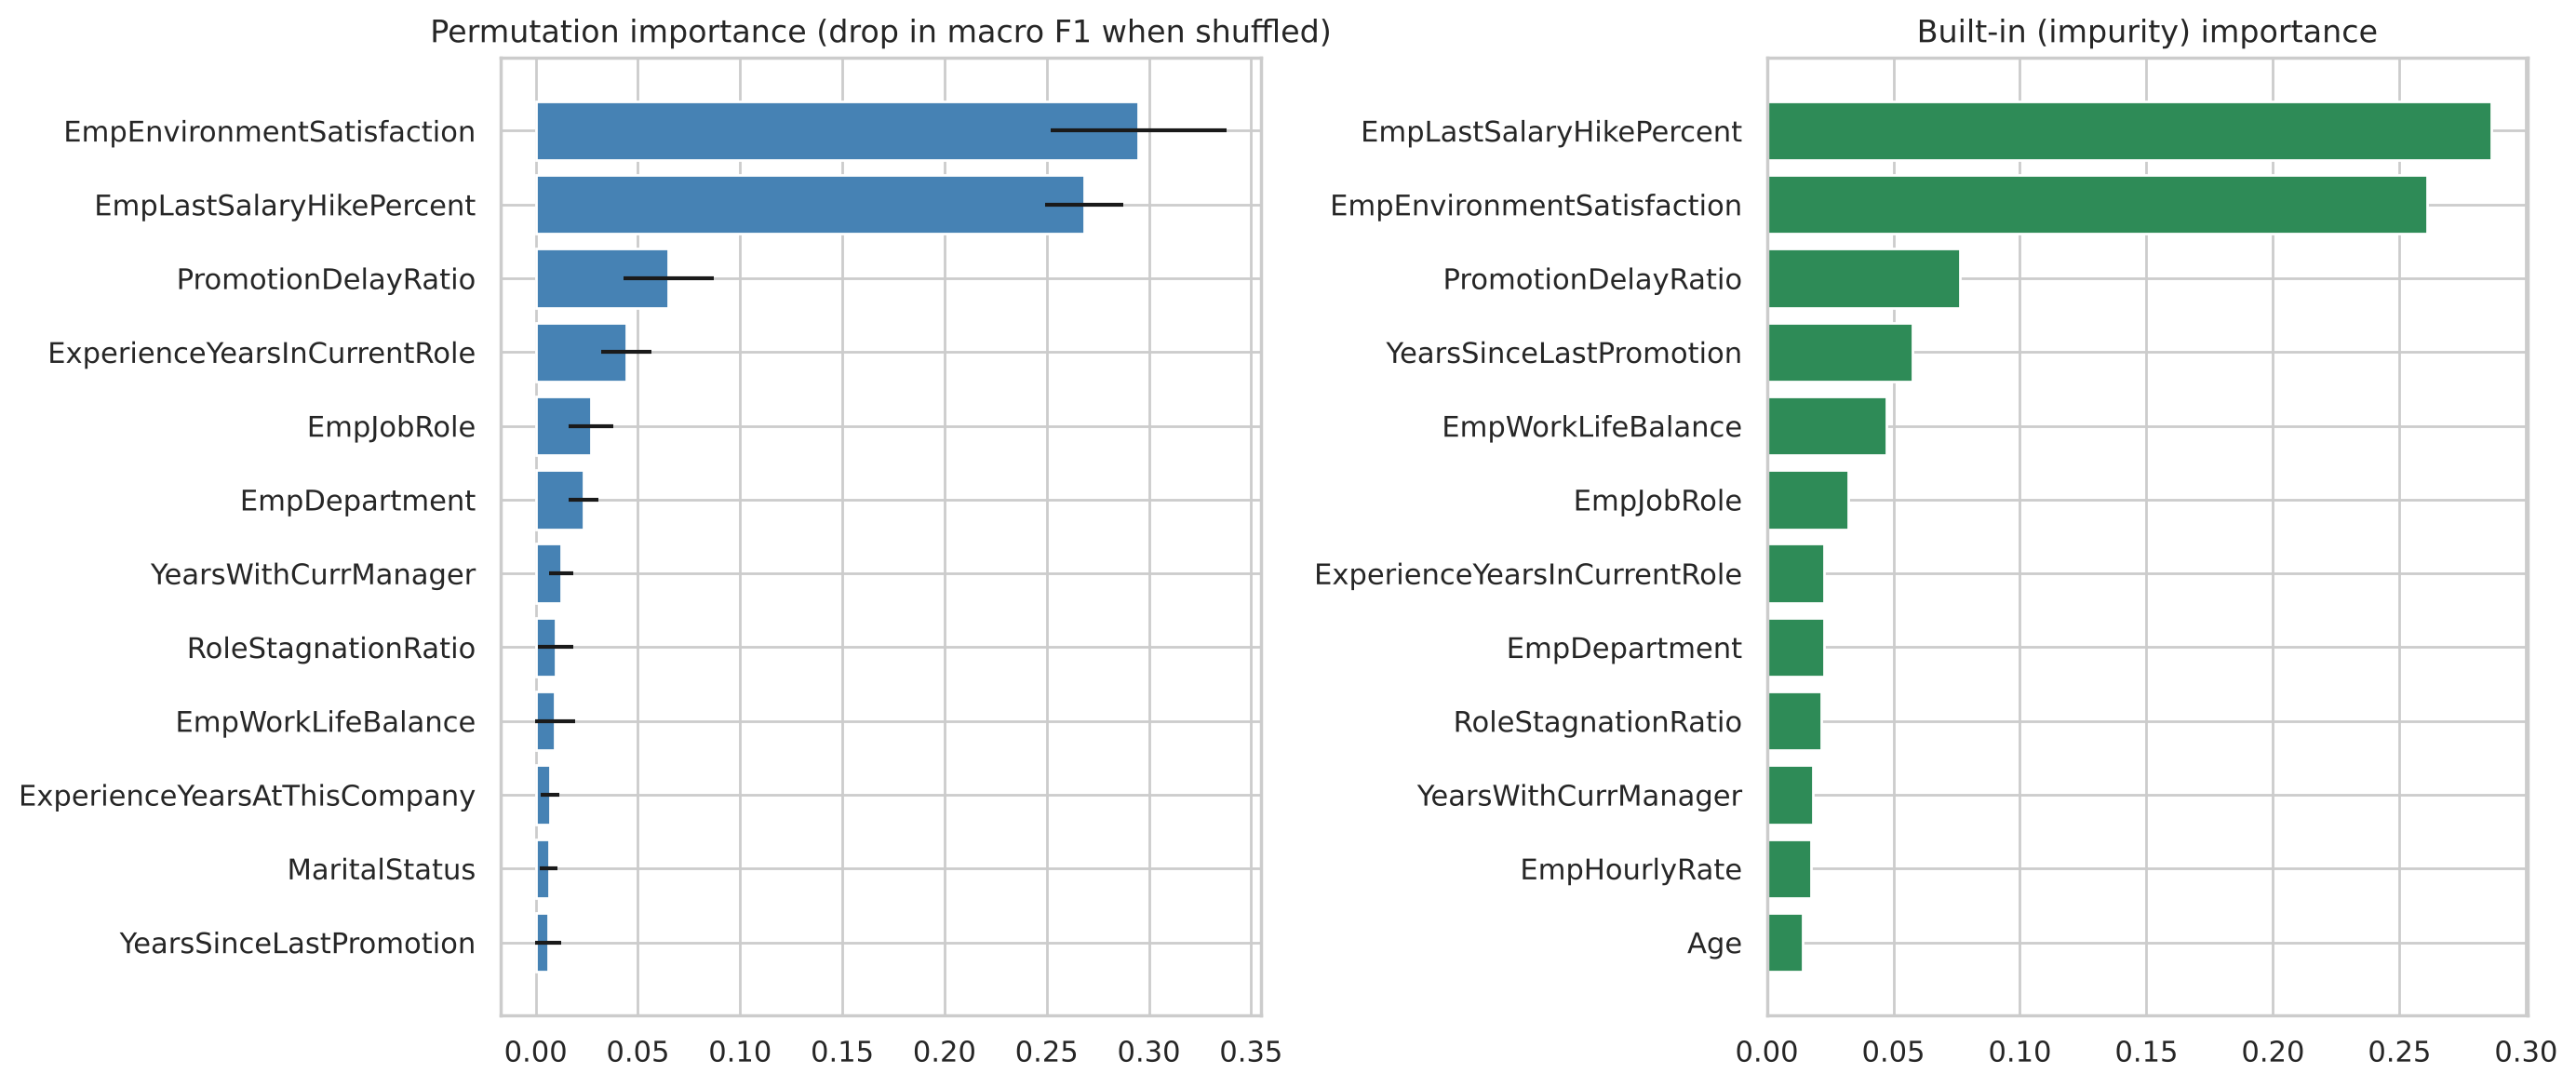

TOP 3 FACTORS: ['EmpEnvironmentSatisfaction', 'EmpLastSalaryHikePercent', 'PromotionDelayRatio']


In [9]:
fig, axes = plt.subplots(1,2, figsize=(14,6))
top = imp.head(12).iloc[::-1]
axes[0].barh(top['feature'], top['permutation_importance'], xerr=top['std'], color='steelblue')
axes[0].set_title('Permutation importance (drop in macro F1 when shuffled)')
top2 = imp.sort_values('builtin_importance', ascending=False).head(12).iloc[::-1]
axes[1].barh(top2['feature'], top2['builtin_importance'], color='seagreen'); axes[1].set_title('Built-in (impurity) importance')
plt.tight_layout(); plt.show()
top3 = imp['feature'].head(3).tolist(); print('TOP 3 FACTORS:', top3)

**Result.** Both methods put the same three factors at the top:

1. **Employee environment satisfaction**
2. **Last salary hike percentage**
3. **Time since last promotion.** The model prefers the engineered ratio `PromotionDelayRatio` (years since last promotion relative to years at the company) to the raw `YearsSinceLastPromotion`. The two carry nearly the same information; when features are strongly correlated, importance gets shared or shifts to whichever the model uses first, which is why the raw column ranks lower. Together they represent one factor: *how long an employee has gone without a promotion*.

The first two factors are far ahead of everything else (permutation importance about 0.27-0.30 versus 0.07 or less for the rest). Department, job role, age, gender and education contribute little once these are known.

In [10]:
# How much do the three factors matter together? Retrain using only them and compare.
top3_cols = imp['feature'].head(3).tolist()
mini_num = [c for c in top3_cols]
mini = Pipeline([('prep', ColumnTransformer([('n', StandardScaler(), mini_num)])),
                 ('model', RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))])
mini.fit(X_train[mini_num], y_train); p = mini.predict(X_test[mini_num])
print('Model using ONLY the top 3 factors: accuracy =', round(accuracy_score(y_test,p),3), ', macro F1 =', round(f1_score(y_test,p,average='macro'),3))
print('Full model                         : accuracy =', round(metrics['test_accuracy'],3), ', macro F1 =', round(metrics['test_macro_f1'],3))
metrics['top3_only_test_accuracy'] = float(accuracy_score(y_test,p)); metrics['top3_only_test_macro_f1'] = float(f1_score(y_test,p,average='macro'))

Model using ONLY the top 3 factors: accuracy = 0.858 , macro F1 = 0.808
Full model                         : accuracy = 0.933 , macro F1 = 0.902


Three inputs alone reach about 86% accuracy and a macro F1 of 0.81, roughly 90% of the full model's macro F1, so they carry most of the useful signal. The remaining gain comes from many smaller factors (years in role, job role, department, years with manager, and so on).

**Department and job role** carry small but real additional signal: their importance is roughly a tenth of that of the top two factors. Department matters mostly as a *label for a group of working conditions*, not as a root cause.

## 6. Is the hiring model realistic? A pre-hire model

The required model is "used to hire employees". But the strongest predictors (environment satisfaction, salary hike, years since last promotion) only exist **after** someone has joined. A hiring decision can only use what is known about a **candidate**: age, education, experience, number of past employers, role applied for, offered pay and level, and so on.

We therefore train a second model on candidate-knowable features only and judge it honestly.

In [11]:
prehire_features = ['Age','Gender','EducationBackground','MaritalStatus','EmpEducationLevel','NumCompaniesWorked',
                    'TotalWorkExperienceInYears','DistanceFromHome','EmpDepartment','EmpJobRole','BusinessTravelFrequency',
                    'EmpHourlyRate','EmpJobLevel','AvgYearsPerCompany']
# Marital status and gender are NOT suitable inputs for a hiring decision (discrimination risk), so we drop them
prehire_features = [c for c in prehire_features if c not in ('Gender','MaritalStatus')]
ph_nom = [c for c in ['EducationBackground','EmpDepartment','EmpJobRole'] if c in prehire_features]
ph_ord = ['BusinessTravelFrequency']
ph_num = [c for c in prehire_features if c not in ph_nom+ph_ord]
ph_prep = ColumnTransformer([('num',StandardScaler(),ph_num),
                             ('nom',OneHotEncoder(handle_unknown='ignore',sparse_output=False),ph_nom),
                             ('ord',OrdinalEncoder(categories=[['Non-Travel','Travel_Rarely','Travel_Frequently']]),ph_ord)])
ph_pipe = Pipeline([('prep',ph_prep),('model',RandomForestClassifier(n_estimators=500,min_samples_leaf=3,class_weight='balanced',random_state=RANDOM_STATE,n_jobs=-1))])
ph_pipe.fit(X_train[prehire_features], y_train)
ph_pred = ph_pipe.predict(X_test[prehire_features])
print('Pre-hire model (test): accuracy =', round(accuracy_score(y_test,ph_pred),3), ', macro F1 =', round(f1_score(y_test,ph_pred,average='macro'),3),
      ', balanced accuracy =', round(balanced_accuracy_score(y_test,ph_pred),3))
print('Always-predict-3 baseline: accuracy =', round((y_test==3).mean(),3), ', macro F1 =', round(f1_score(y_test,np.full(len(y_test),3),average='macro'),3))
print(); print(classification_report(y_test, ph_pred, target_names=['2','3','4'], zero_division=0))
metrics['prehire_test_accuracy'] = float(accuracy_score(y_test,ph_pred)); metrics['prehire_test_macro_f1']=float(f1_score(y_test,ph_pred,average='macro'))
metrics['prehire_test_balanced_accuracy']=float(balanced_accuracy_score(y_test,ph_pred)); metrics['prehire_features']=prehire_features

Pre-hire model (test): accuracy = 0.496 , macro F1 = 0.335 , balanced accuracy = 0.37
Always-predict-3 baseline: accuracy = 0.729 , macro F1 = 0.281

              precision    recall  f1-score   support

           2       0.24      0.51      0.33        39
           3       0.75      0.56      0.64       175
           4       0.04      0.04      0.04        26

    accuracy                           0.50       240
   macro avg       0.34      0.37      0.33       240
weighted avg       0.59      0.50      0.52       240



**Honest conclusion on hiring.** Using only candidate information, the model is **barely better than chance**: balanced accuracy is about 0.37 where pure chance between three classes gives 0.33, its overall accuracy (about 50%) is far below the 73% of simply guessing 3, and it essentially cannot identify future top performers (precision for rating 4 is about 4%). Performance at INX is mainly determined by **what happens after joining** (the working environment, pay progression, promotion), not by who was hired. This means:

- The full model is best used on **current employees**, to find who is at risk and why.
- Recruitment screening alone will not fix performance. Retention conditions matter more than selection.
- For hiring, the pre-hire model should be treated as a weak, supporting signal at most, never a screening rule. (Gender and marital status were deliberately left out of it to avoid discrimination risk.)

## 7. Clear indicators of lower performers (explainable rules)

The CEO asked for clear indicators so any action can be targeted. A shallow decision tree gives plain if-then rules for flagging rating-2 employees. It is less accurate than the ensemble but fully explainable.

In [12]:
y_low = (y_train == 2).astype(int)
rule_cols = ['EmpEnvironmentSatisfaction','EmpLastSalaryHikePercent','YearsSinceLastPromotion','EmpWorkLifeBalance',
             'ExperienceYearsInCurrentRole','YearsWithCurrManager','ExperienceYearsAtThisCompany','EmpJobLevel','Age','EmpHourlyRate']
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE).fit(X_train[rule_cols], y_low)
print(export_text(tree, feature_names=rule_cols))
yl_test = (y_test==2).astype(int); tp = tree.predict(X_test[rule_cols])
from sklearn.metrics import precision_score, recall_score
print('Rule tree on test set: recall of rating-2 employees =', round(recall_score(yl_test,tp),2), ', precision =', round(precision_score(yl_test,tp),2))

|--- EmpEnvironmentSatisfaction <= 2.50
|   |--- YearsSinceLastPromotion <= 0.50
|   |   |--- EmpHourlyRate <= 91.50
|   |   |   |--- class: 0
|   |   |--- EmpHourlyRate >  91.50
|   |   |   |--- class: 0
|   |--- YearsSinceLastPromotion >  0.50
|   |   |--- ExperienceYearsInCurrentRole <= 3.50
|   |   |   |--- class: 1
|   |   |--- ExperienceYearsInCurrentRole >  3.50
|   |   |   |--- class: 1
|--- EmpEnvironmentSatisfaction >  2.50
|   |--- EmpWorkLifeBalance <= 1.50
|   |   |--- class: 0
|   |--- EmpWorkLifeBalance >  1.50
|   |   |--- class: 0

Rule tree on test set: recall of rating-2 employees = 0.92 , precision = 0.65


In [13]:
# The simplest indicator of all: low environment satisfaction (1-2) combined with a gap since last promotion
flag = lambda d: (d['EmpEnvironmentSatisfaction']<=2) & (d['YearsSinceLastPromotion']>=1)
all_flag = flag(df)
print(f'Employees flagged by the simple rule: {all_flag.sum()} of {len(df)} ({100*all_flag.mean():.0f}%)')
print(f'Share of all rating-2 employees caught: {100*(all_flag & (df.PerformanceRating==2)).sum()/(df.PerformanceRating==2).sum():.0f}%')
print(f'Share of flagged employees who are rating 2: {100*(df[all_flag].PerformanceRating==2).mean():.0f}%  (vs {100*(df.PerformanceRating==2).mean():.0f}% overall)')

Employees flagged by the simple rule: 281 of 1200 (23%)
Share of all rating-2 employees caught: 96%
Share of flagged employees who are rating 2: 66%  (vs 16% overall)


The rules show that **low environment satisfaction** is the core indicator, and a **gap since last promotion** sharpens it. Targeting this group focuses attention on a minority of employees and leaves the rest untouched, which protects overall morale (see recommendations).

## 8. Out-of-fold predictions for every employee

To list employees at risk without the optimism of scoring them with a model that has already seen them, each employee is predicted by a model that was **not** trained on that employee (5-fold out-of-fold predictions).

In [14]:
from sklearn.base import clone
oof_proba = cross_val_predict(clone(best_pipe), X, y, cv=cv, method='predict_proba', n_jobs=-1)
classes = [2,3,4]
oof = pd.DataFrame({'EmpNumber':df['EmpNumber'], 'EmpDepartment':df['EmpDepartment'], 'EmpJobRole':df['EmpJobRole'],
                    'ActualRating':y, 'PredictedRating':np.array(classes)[oof_proba.argmax(1)],
                    'Prob_Rating2':oof_proba[:,0], 'Prob_Rating3':oof_proba[:,1], 'Prob_Rating4':oof_proba[:,2]}).round(4)
print('Out-of-fold accuracy:', round(accuracy_score(oof.ActualRating, oof.PredictedRating),3), ' macro F1:', round(f1_score(oof.ActualRating, oof.PredictedRating, average='macro'),3))
oof.head()

Out-of-fold accuracy: 0.918  macro F1: 0.883


,EmpNumber,EmpDepartment,EmpJobRole,ActualRating,PredictedRating,Prob_Rating2,Prob_Rating3,Prob_Rating4
0,E1001000,Sales,Sales Executive,3,3,0.0000,0.9733,0.0267
1,E1001006,Sales,Sales Executive,3,3,0.0000,1.0000,0.0000
2,E1001007,Sales,Sales Executive,4,4,0.0133,0.0067,0.9800
3,E1001009,Human Resources,Manager,3,2,0.9633,0.0367,0.0000
4,E1001010,Sales,Sales Executive,3,2,0.8967,0.0567,0.0467


## 9. Save the trained model and results

In [15]:
# Refit the selected model on ALL employees for deployment (the evaluation above used the train/test split)
final_model = clone(best_pipe).fit(X, y)
prehire_final = clone(ph_pipe).fit(X[prehire_features], y)
joblib.dump(final_model, ART/'performance_model.joblib')
joblib.dump(prehire_final, ART/'prehire_model.joblib')
meta = {'input_columns': X.columns.tolist(), 'classes': classes, 'metrics': metrics, 'top3_factors': top3,
        'ordinal_travel_order': ['Non-Travel','Travel_Rarely','Travel_Frequently']}
(ART/'model_metadata.json').write_text(json.dumps(meta, indent=2))
comparison.round(4).to_csv(ART/'model_comparison.csv', index=False)
imp.round(5).to_csv(ART/'feature_importance.csv', index=False)
oof.to_csv(ART/'out_of_fold_predictions.csv', index=False)
pd.DataFrame(cm, index=['actual_2','actual_3','actual_4'], columns=['pred_2','pred_3','pred_4']).to_csv(ART/'test_confusion_matrix.csv')
print(sorted(p.name for p in ART.iterdir()))

['feature_importance.csv', 'model_comparison.csv', 'model_metadata.json', 'out_of_fold_predictions.csv', 'performance_model.joblib', 'prehire_model.joblib', 'test_confusion_matrix.csv']


## Summary

- **Selected model:** tuned **Random Forest**, chosen by cross-validated macro F1 (Gradient Boosting was a very close second), evaluated once on a held-out test set: about 93% accuracy, macro F1 0.90.
- **Top 3 factors:** environment satisfaction, last salary hike percentage, time since last promotion.
- **Hiring:** a candidate-only model has little predictive power; performance is mostly shaped after joining.
- **Indicators:** low environment satisfaction (plus time since promotion) identifies almost all lower performers.
- Model, metrics, importances and out-of-fold predictions are saved in `src/models/artifacts/` for the prediction notebook.